# InSight Mars seismic data

Hoi Fu Lee & Qili Andy Dai

Aerospace Science and Earth Informatics Double Major Program  
Department of Earth and Environmental Sciences  

Contact: qilidai@cuhk.edu.hk

InSight’s SEIS instrument gave us a way to study how Mars shakes and how seismic waves travel through the planet. In a single-station record, an arrival may be difficult to distinguish from background noise, and different marsquake classes can concentrate their energy in different frequency ranges. This tutorial uses four events from the Marsquake Service catalogue to show how to recognise those differences. 

Run the cells in order. Downloads go to `data/`, and plots are saved in `figures/` under the working directory.

## 1. Check environment and dependencies

Use any Python environment with `numpy`, `scipy`, `matplotlib`, `obspy`, and `ipykernel`. If an import fails, install the missing package in the environment used by this notebook (for example, `%pip install numpy scipy matplotlib obspy ipykernel`), then restart the kernel. The working directory printed below is where downloads will be saved.

In [55]:
%pip install numpy scipy matplotlib obspy ipykernel

Note: you may need to restart the kernel to use updated packages.


In [56]:
import sys
import ssl
from pathlib import Path
from urllib.request import Request, urlopen
import xml.etree.ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt
from obspy import read, UTCDateTime
from obspy.clients.fdsn import Client

work_dir = Path.cwd()
data_dir = work_dir / "data"
figure_dir = work_dir / "figures"
data_dir.mkdir(exist_ok=True)
figure_dir.mkdir(exist_ok=True)

print("Python:", sys.executable)
print("Working directory:", work_dir)
print("Imports OK")

Python: /Users/qilidai/opt/miniconda3/envs/fk/bin/python
Working directory: /Users/qilidai/Desktop/CUHK/ug_students/mars_seismic_data_download
Imports OK


## 2. Download and search the MQS catalogue

The MQS v14 QuakeML catalogue is at:

https://www.seis-insight.eu/static/mqs-catalogs/v14/events_extended_multiorigin_v14_2023-01-01.xml

Download it once, parse event name, type and origin time, then look up a few example events.

In [57]:
import ssl
from pathlib import Path
from urllib.request import Request, urlopen
import xml.etree.ElementTree as ET

catalog_url = ("https://www.seis-insight.eu/static/mqs-catalogs/v14/events_extended_multiorigin_v14_2023-01-01.xml")
catalog_path = data_dir / "mqs_v14_events.xml"

def download_catalog(url, save_path):
    if save_path.is_file() and save_path.stat().st_size > 0:
        print("Using cached catalogue:", save_path)
        return

    ssl_context = ssl._create_unverified_context()
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, context=ssl_context) as response:
        save_path.write_bytes(response.read())
    print(f"Saved: {save_path} ({save_path.stat().st_size:,} bytes)")

download_catalog(catalog_url, catalog_path)


def tag_name(element):
    return element.tag.split("}", 1)[-1]


def find_text(element, wanted_tag):
    for ev in element:
        if tag_name(ev) == wanted_tag and ev.text:
            return ev.text.strip()
    return None


def get_event_name(event_element):
    for desc in event_element:
        if tag_name(desc) != "description":
            continue
        desc_type = find_text(desc, "type")
        desc_text = find_text(desc, "text")
        if desc_type == "earthquake name" and desc_text:
            return desc_text
    return None


def get_event_type(event_element):
    for data in event_element.iter():
        if tag_name(data) == "type" and data.text and "MarsEventType#" in data.text:
            return data.text.split("#")[-1]
    return None


def get_origin_time(event_element):
    for origin in event_element.iter():
        if tag_name(origin) != "origin":
            continue
        for sub in origin.iter():
            if tag_name(sub) == "value" and sub.text and "T" in sub.text:
                return sub.text.strip()
        break
    return None


def parse_catalog(xml_path):
    root = ET.parse(xml_path).getroot()
    catalog = {}

    for event in root.iter():
        if tag_name(event) != "event":
            continue

        name = get_event_name(event)

        catalog[name] = {
            "type": get_event_type(event) or "UNKNOWN",
            "origin_time": get_origin_time(event) or "N/A",
        }

    return catalog


catalog = parse_catalog(catalog_path)

targets = ["S0533a", "S0793a", "S0794a", "S0981c", "S1000a", "S0173a", "S0235b"]

print(f"{'Event':<10} {'Type':<22} {'Origin time (UTC)'}")
for event_id in targets:
    info = catalog.get(event_id)
    if info is None:
        print(f"{event_id:<10} (not found)")
    else:
        print(f"{event_id:<10} {info['type']:<22} {info['origin_time']}")

Using cached catalogue: /Users/qilidai/Desktop/CUHK/ug_students/mars_seismic_data_download/data/mqs_v14_events.xml
Event      Type                   Origin time (UTC)
S0533a     VERY_HIGH_FREQUENCY    2020-05-27T13:43:03.163214Z
S0793a     VERY_HIGH_FREQUENCY    2021-02-18T19:31:23.20042Z
S0794a     VERY_HIGH_FREQUENCY    2021-02-19T01:21:16.645281Z
S0981c     VERY_HIGH_FREQUENCY    2021-08-31T03:59:01.746379Z
S1000a     BROADBAND              2021-09-18T17:46:20.639751Z
S0173a     LOW_FREQUENCY          2019-05-23T02:19:09.852879Z
S0235b     BROADBAND              2019-07-26T12:15:38.748239Z


## 3. Select four example events

Use one event each from the LF, BB, HF and VF classes. For each event, use a 1,500 s record starting at the specified UTC time and select 100–200 s after that start as the noise window. Keep the event-specific P-wave signal windows.

In [58]:
events = {
    "S0173a": {
        "type": "LF",
        "start": "2019-05-23T02:09:24",
        "P_arrival": "2019-05-23T02:22:59",
        "signal_win": ("2019-05-23T02:22:59", "2019-05-23T02:24:56"),
    },
    "S0235b": {
        "type": "BB",
        "start": "2019-07-26T12:14:20",
        "P_arrival": "2019-07-26T12:19:18",
        "signal_win": ("2019-07-26T12:19:18", "2019-07-26T12:20:31"),
    },
    "S0340a": {
        "type": "HF",
        "start": "2019-11-11T09:46:01",
        "P_arrival": "2019-11-11T09:58:05",
        "signal_win": ("2019-11-11T09:58:05", "2019-11-11T10:01:58"),
    },
    "S0794a": {
        "type": "VF",
        "start": "2021-02-19T01:14:00",
        "P_arrival": "2021-02-19T01:26:21.545601",
        "signal_win": ("2021-02-19T01:26:25.331139", "2021-02-19T01:29:16.540234"),
    },
}

for meta in events.values():
    start = UTCDateTime(meta["start"])
    meta["end"] = start + 1500
    meta["noise_win"] = (start + 100, start + 200)

for eid, meta in events.items():
    cat_type = catalog.get(eid, {}).get("type", "?")
    print(f"{eid:8s}  notebook={meta['type']:3s}  catalogue={cat_type:20s}  "
          f"{meta['start']} -> {meta['end']}")

S0173a    notebook=LF   catalogue=LOW_FREQUENCY         2019-05-23T02:09:24 -> 2019-05-23T02:34:24.000000Z
S0235b    notebook=BB   catalogue=BROADBAND             2019-07-26T12:14:20 -> 2019-07-26T12:39:20.000000Z
S0340a    notebook=HF   catalogue=HIGH_FREQUENCY        2019-11-11T09:46:01 -> 2019-11-11T10:11:01.000000Z
S0794a    notebook=VF   catalogue=VERY_HIGH_FREQUENCY   2021-02-19T01:14:00 -> 2021-02-19T01:39:00.000000Z


## 4. Download and save vertical displacement

Download the 20 Hz recordings at XB.ELYSE.02. Following the event downloader, retrieve the instrument response, convert each recorded axis to displacement in metres, and rotate to vertical. 

In [59]:
from obspy import read_inventory
from obspy.signal.rotate import rotate2zne

network, station, location, channel = "XB", "ELYSE", "02", "BH?"


def download_recording(event_id, meta, client):
    outfile = data_dir / f"{event_id}_02_BH_1500s.mseed"
    if outfile.is_file() and outfile.stat().st_size > 0:
        print(f"  {event_id}: loaded")
        return read(str(outfile))
    t0, t1 = UTCDateTime(meta["start"]), UTCDateTime(meta["end"])
    print(f"  {event_id}: downloading {t0} - {t1} ...")
    st = client.get_waveforms(network, station, location, channel, t0, t1)
    if len(st) == 0:
        raise RuntimeError(f"No data returned for {event_id}")
    st.write(str(outfile), format="MSEED")
    print(f"  {event_id}: saved {outfile.name} ({len(st)} traces)")
    return st

def load_response(client):
    inventory_path = data_dir / "ELYSE_02_BH_response.xml"
    if inventory_path.is_file():
        inventory = read_inventory(str(inventory_path))
    else:
        inventory = client.get_stations(
            network="XB", station="ELYSE", location="02", channel="BH?",
            starttime=min(UTCDateTime(meta["start"]) for meta in events.values()),
            endtime=max(UTCDateTime(meta["end"]) for meta in events.values()),
            level="response",
        )
        inventory.write(str(inventory_path), format="STATIONXML")
    return inventory

def to_displacement(trace, inventory):
    return trace.remove_response(
        inventory=inventory, output="DISP",
        pre_filt=(0.005, 0.01, 8.0, 10.0), taper_fraction=0.05,
    )

def vertical_trace(stream, inventory):
    stream = stream.select(location="02", sampling_rate=20.0)
    if stream.select(channel="BHZ"):
        return to_displacement(stream.select(channel="BHZ")[0].copy(), inventory)

    axes = [stream.select(channel=code) for code in ("BHU", "BHV", "BHW")]
    if any(len(group) != 1 for group in axes):
        raise ValueError("Expected one continuous BHU, BHV and BHW trace at XB.ELYSE.02.")
    traces = [group[0].copy() for group in axes]
    fs = traces[0].stats.sampling_rate
    start = max(tr.stats.starttime for tr in traces)
    end = min(tr.stats.endtime for tr in traces)
    npts = int(np.floor((end - start) * fs + 1e-6)) + 1
    if npts < 2:
        raise ValueError("The three instrument channels have no common time interval.")

    rotation_inputs = []
    for tr in traces:
        to_displacement(tr, inventory)
        orientation = inventory.get_orientation(tr.id, start)
        tr.interpolate(fs, method="lanczos", a=20, starttime=start, npts=npts)
        rotation_inputs.extend((tr.data, orientation["azimuth"], orientation["dip"]))
    z, _, _ = rotate2zne(*rotation_inputs)
    vertical = traces[0]
    vertical.data = z
    vertical.stats.channel = "BHZ"
    return vertical

unfiltered_z = {}
client = None
for eid, meta in events.items():
    outfile = data_dir / f"{eid}_02_BHZ_1500s_DISP.mseed"
    if outfile.is_file():
        unfiltered_z[eid] = read(str(outfile))[0]
        print(f"{eid}: loaded cached Z displacement")
        continue

    if client is None:
        client = Client("https://service.earthscope.org")
        inventory = load_response(client)
    recording = download_recording(eid, meta, client)
    trace = vertical_trace(recording, inventory)
    trace.write(str(outfile), format="MSEED", encoding="FLOAT64")
    unfiltered_z[eid] = trace
    print(f"{eid}: saved Z displacement in metres to {outfile.name}")


  S0173a: loaded
S0173a: saved Z displacement in metres to S0173a_02_BHZ_1500s_DISP.mseed
  S0235b: loaded
S0235b: saved Z displacement in metres to S0235b_02_BHZ_1500s_DISP.mseed
  S0340a: loaded
S0340a: saved Z displacement in metres to S0340a_02_BHZ_1500s_DISP.mseed
  S0794a: loaded
S0794a: saved Z displacement in metres to S0794a_02_BHZ_1500s_DISP.mseed


## 5. Taper and filter the vertical displacement

Use 0.1–0.5 Hz for LF, 0.1–1.5 Hz for BB, 2–4 Hz for HF, and 2–7 Hz for VF.

In [60]:
bands = {"LF": (0.1, 0.5), "BB": (0.1, 1.5), "HF": (2.0, 4.0), "VF": (2.0, 7.0)}
processed = {}
for eid, displacement in unfiltered_z.items():
    tr = displacement.copy()
    fmin, fmax = bands[events[eid]["type"]]
    if fmax >= tr.stats.sampling_rate / 2:
        raise ValueError(f"{eid}: {fmax:g} Hz must be below the Nyquist frequency.")
    tr.detrend("linear")
    tr.taper(max_percentage=0.05, type="hann", side="both")
    tr.filter("bandpass", freqmin=fmin, freqmax=fmax, corners=2, zerophase=True)
    processed[eid] = tr
    print(f"{eid}: {tr.id}, {tr.stats.sampling_rate:g} Hz, bandpass {fmin:g}–{fmax:g} Hz")


S0173a: XB.ELYSE.02.BHZ, 20 Hz, bandpass 0.1–0.5 Hz
S0235b: XB.ELYSE.02.BHZ, 20 Hz, bandpass 0.1–1.5 Hz
S0340a: XB.ELYSE.02.BHZ, 20 Hz, bandpass 2–4 Hz
S0794a: XB.ELYSE.02.BHZ, 20 Hz, bandpass 2–7 Hz


## 6. Vertical component

The grey band marks the noise window, and the blue band marks the P-wave signal window. The dashed line marks the P arrival. 

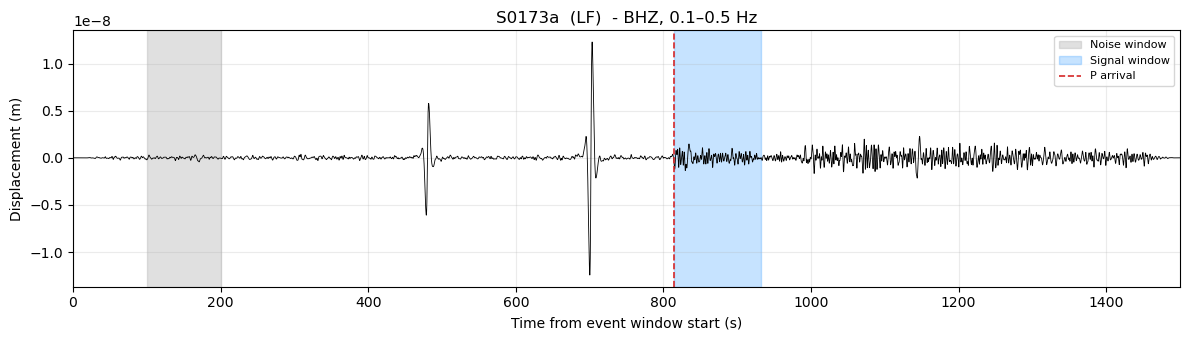

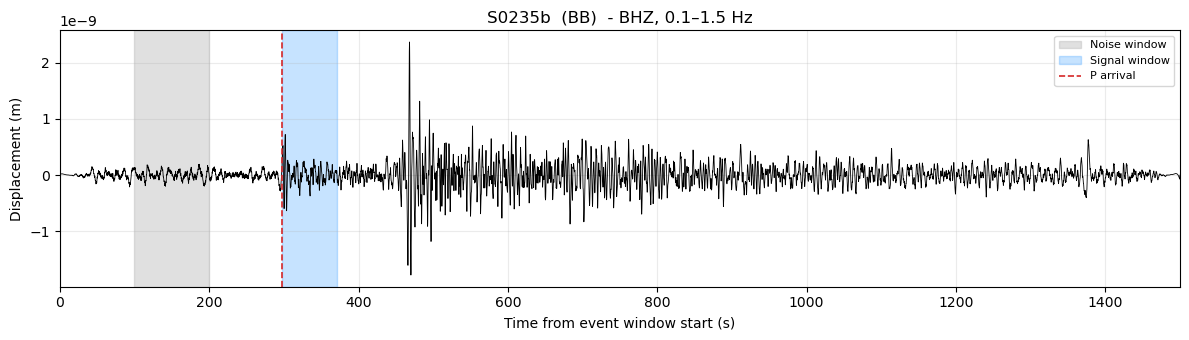

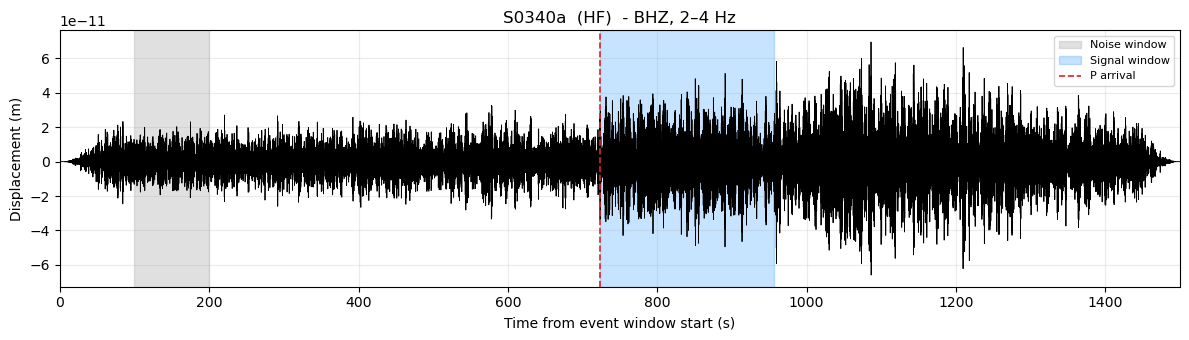

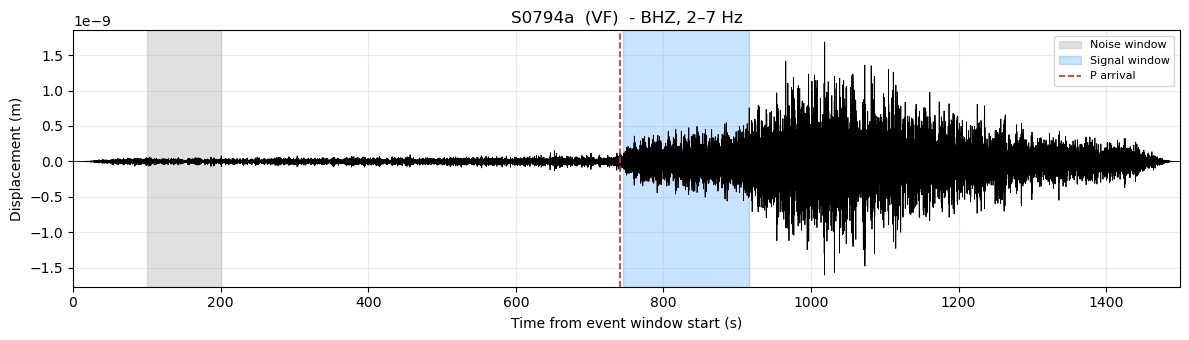

In [61]:
def plot_waveform_with_windows(eid, meta, tr):
    t0 = UTCDateTime(meta["start"])
    times = tr.times(reftime=t0)
    noise_t0 = UTCDateTime(meta["noise_win"][0]) - t0
    noise_t1 = UTCDateTime(meta["noise_win"][1]) - t0
    sig_t0 = UTCDateTime(meta["signal_win"][0]) - t0
    sig_t1 = UTCDateTime(meta["signal_win"][1]) - t0
    p_arr = UTCDateTime(meta["P_arrival"]) - t0

    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(times, tr.data, lw=0.6, color="k")
    ax.axvspan(noise_t0, noise_t1, color="0.7", alpha=0.4, label="Noise window")
    ax.axvspan(sig_t0, sig_t1, color="dodgerblue", alpha=0.25, label="Signal window")
    ax.axvline(p_arr, color="C3", ls="--", lw=1.2, label="P arrival")
    ax.set_xlim(0, 1500)
    ax.set_xlabel("Time from event window start (s)")
    ax.set_ylabel("Displacement (m)")
    fmin, fmax = bands[meta["type"]]
    ax.set_title(f"{eid}  ({meta['type']})  - {tr.stats.channel}, {fmin:g}–{fmax:g} Hz")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(figure_dir / f"{eid}_waveform.png", dpi=150, bbox_inches="tight")
    plt.show()

for eid, meta in events.items():
    if eid in processed:
        plot_waveform_with_windows(eid, meta, processed[eid])

## 7. Compare displacement amplitude spectra

For each window, remove its mean, apply a Hann taper, and compute a one-sided FFT amplitude spectrum. 

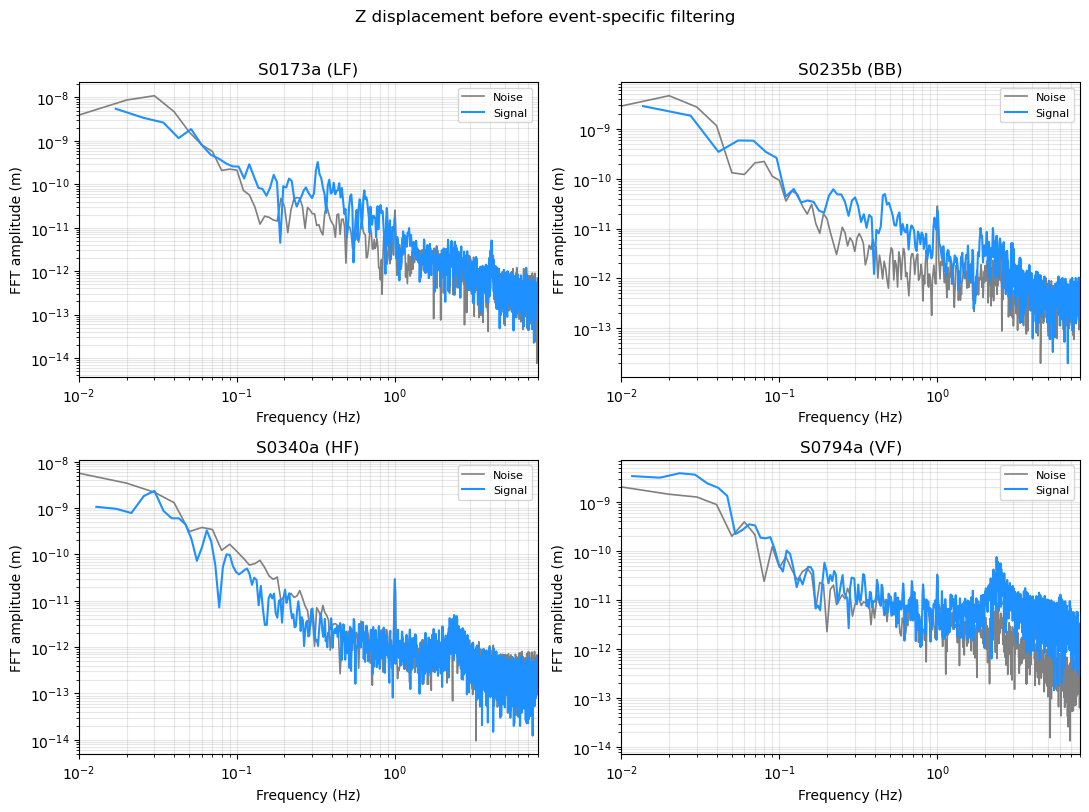

In [62]:
def fft_amplitude(trace, start, end):
    window = trace.copy().trim(UTCDateTime(start), UTCDateTime(end), nearest_sample=False)
    data = window.data.astype(float)
    if len(data) < 4:
        raise ValueError("The spectral window contains too few samples.")
    taper = np.hanning(len(data))
    amplitude = np.abs(np.fft.rfft((data - data.mean()) * taper)) / taper.sum()
    amplitude[1:] *= 2
    if len(data) % 2 == 0:
        amplitude[-1] /= 2
    return np.fft.rfftfreq(len(data), d=trace.stats.delta), amplitude

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=False)
axes = axes.ravel()

for ax, (eid, meta) in zip(axes, events.items()):
    if eid not in unfiltered_z:
        ax.set_visible(False)
        continue
    tr = unfiltered_z[eid]
    f_n, a_n = fft_amplitude(tr, *meta["noise_win"])
    f_s, a_s = fft_amplitude(tr, *meta["signal_win"])
    fmin, fmax = 0.01, 8.0
    noise = (f_n >= fmin) & (f_n <= fmax) & np.isfinite(a_n) & (a_n > 0)
    signal = (f_s >= fmin) & (f_s <= fmax) & np.isfinite(a_s) & (a_s > 0)
    ax.loglog(f_n[noise], a_n[noise], color="0.5", lw=1.2, label="Noise")
    ax.loglog(f_s[signal], a_s[signal], color="dodgerblue", lw=1.5, label="Signal")
    ax.set_title(f"{eid} ({meta['type']})")
    ax.set_ylabel("FFT amplitude (m)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlim(fmin, fmax)
    ax.set_xlabel("Frequency (Hz)")
    visible_amplitude = np.concatenate([a_n[noise], a_s[signal]])
    if visible_amplitude.size:
        lo, hi = np.log10([visible_amplitude.min(), visible_amplitude.max()])
        padding = max(0.06, 0.05 * (hi - lo))
        ax.set_ylim(10 ** (lo - padding), 10 ** (hi + padding))

fig.suptitle("Z displacement before event-specific filtering", y=1.01)
fig.tight_layout()
fig.savefig(figure_dir / "spectra_comparison.png", dpi=150, bbox_inches="tight")
plt.show()